In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install -q -U ultralytics pyyaml

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.5/45.5 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.8 MB/s eta 0:00:00


## Mount Drive and install packages

In [ ]:
# ============================================================
# OralScan_AI — AI_Y1 YOLO26-M Segmentation
# Cell 1: Environment setup
# ============================================================

import os
import sys
import torch
import ultralytics

print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("CUDA available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU detect nahi hua. Colab mein Runtime > Change runtime type > T4 GPU select karein."
    )

print("GPU:", torch.cuda.get_device_name(0))
!nvidia-smi

Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
Ultralytics: 8.4.115
CUDA available: True
GPU: Tesla T4
Tue Aug  4 04:54:36 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P0             27W /   70W |     219MiB /  15360MiB |      0%      Default |
|  

## Complete dataset preparation, merging and class remapping

In [ ]:
# ============================================================
# Cell 2: Discover, validate, merge and remap all four datasets
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict
import shutil
import zipfile
import yaml
import json
import re

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

DRIVE_DATASET_ROOT = Path(
    "/content/drive/MyDrive/AI_C1 and AI_Y1/DataSet"
)

DRIVE_PROJECT_ROOT = Path(
    "/content/drive/MyDrive/AI_C1 and AI_Y1"
)

DRIVE_OUTPUT_ROOT = DRIVE_PROJECT_ROOT / "AI_Y1_Training"

LOCAL_ROOT = Path("/content/OralScan_AI_Y1")
LOCAL_SOURCE_ROOT = LOCAL_ROOT / "source"
LOCAL_MERGED_ROOT = LOCAL_ROOT / "merged_dataset"

EXPECTED_TOTAL_IMAGES = 817

IMAGE_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".webp",
    ".bmp", ".tif", ".tiff"
}

FINAL_CLASS_NAMES = {
    0: "gum_region",
    1: "lesion",
}

if not DRIVE_DATASET_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset path nahi mila:\n{DRIVE_DATASET_ROOT}\n\n"
        "Google Drive folder ka exact spelling/capitalization check karein."
    )

DRIVE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

print("Dataset source:", DRIVE_DATASET_ROOT)
print("Training outputs:", DRIVE_OUTPUT_ROOT)

# ------------------------------------------------------------
# CLEAN LOCAL WORKSPACE
# ------------------------------------------------------------

if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)

LOCAL_SOURCE_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# COPY OR EXTRACT SOURCE DATASETS
# ------------------------------------------------------------

zip_files = sorted(DRIVE_DATASET_ROOT.rglob("*.zip"))

if zip_files:
    print(f"\n{len(zip_files)} ZIP file(s) mile. Extract kiye ja rahe hain.")

    for index, zip_path in enumerate(zip_files, start=1):
        destination = LOCAL_SOURCE_ROOT / f"{index:02d}_{zip_path.stem}"
        destination.mkdir(parents=True, exist_ok=True)

        print("Extracting:", zip_path.name)

        with zipfile.ZipFile(zip_path, "r") as archive:
            archive.extractall(destination)

else:
    print("\nZIP files nahi mile. Extracted folders local Colab storage mein copy honge.")

    shutil.copytree(
        DRIVE_DATASET_ROOT,
        LOCAL_SOURCE_ROOT,
        dirs_exist_ok=True,
    )

print("Local source ready:", LOCAL_SOURCE_ROOT)

# ------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------

def normalize_name(value: str) -> str:
    value = str(value).strip().lower()
    value = value.replace("-", "_").replace(" ", "_")
    value = re.sub(r"_+", "_", value)
    return value


def normalize_names(names):
    """Convert list/dictionary YAML class names to {int: str}."""
    if isinstance(names, list):
        return {index: str(name) for index, name in enumerate(names)}

    if isinstance(names, dict):
        return {int(key): str(value) for key, value in names.items()}

    raise TypeError(f"Unsupported names format: {type(names)}")


def find_dataset_root(yaml_path: Path) -> Path:
    return yaml_path.parent


def resolve_split(dataset_root: Path, split: str) -> Path:
    candidates = [split]

    if split == "valid":
        candidates.extend(["val", "validation"])

    for candidate in candidates:
        path = dataset_root / candidate

        if (
            path.is_dir()
            and (path / "images").is_dir()
            and (path / "labels").is_dir()
        ):
            return path

    # Handle extra nested export folder
    for candidate in candidates:
        matches = [
            path for path in dataset_root.rglob(candidate)
            if (
                path.is_dir()
                and (path / "images").is_dir()
                and (path / "labels").is_dir()
            )
        ]

        if len(matches) == 1:
            return matches[0]

    raise FileNotFoundError(
        f"'{split}' split nahi mila:\n{dataset_root}"
    )


def identify_dataset(names: dict):
    """
    Return:
      dataset type
      filename prefix
      source-to-final class mapping
    """

    normalized = {
        class_id: normalize_name(class_name)
        for class_id, class_name in names.items()
    }

    combined = " ".join(normalized.values())

    # Normal Mucosa dataset
    if len(normalized) == 1 and "processing_area" in combined:
        return {
            "dataset_type": "normal_mucosa",
            "prefix": "normal",
            "class_map": {
                0: 0,  # processing_area -> gum_region
            },
        }

    # Cancer
    if "cancer" in combined:
        return {
            "dataset_type": "cancer",
            "prefix": "cancer",
            "class_map": {
                0: 1,  # disease polygon -> lesion
                1: 0,  # processing_area -> gum_region
            },
        }

    # Leukoplakia-like must be checked before plain leukoplakia
    if (
        "leukoplakia_like" in combined
        or "leukoplakia_like_detection" in combined
    ):
        return {
            "dataset_type": "leukoplakia_like",
            "prefix": "leukoplakia_like",
            "class_map": {
                0: 1,
                1: 0,
            },
        }

    # Leukoplakia
    if "leukoplakia" in combined:
        return {
            "dataset_type": "leukoplakia",
            "prefix": "leukoplakia",
            "class_map": {
                0: 1,
                1: 0,
            },
        }

    raise RuntimeError(
        "Dataset type identify nahi hua.\n"
        f"Class names: {names}"
    )


def list_images(directory: Path):
    return sorted(
        path for path in directory.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )


def remap_segmentation_label(
    source_label: Path,
    destination_label: Path,
    class_map: dict,
):
    """
    YOLO segmentation format:
    class_id x1 y1 x2 y2 x3 y3 ...
    """

    if not source_label.exists():
        destination_label.write_text("", encoding="utf-8")
        return {
            "objects": 0,
            "empty": True,
            "missing": True,
            "class_counts": {},
        }

    text = source_label.read_text(encoding="utf-8").strip()

    if not text:
        destination_label.write_text("", encoding="utf-8")
        return {
            "objects": 0,
            "empty": True,
            "missing": False,
            "class_counts": {},
        }

    output_lines = []
    class_counts = Counter()

    for line_number, raw_line in enumerate(text.splitlines(), start=1):
        line = raw_line.strip()

        if not line:
            continue

        tokens = line.split()

        try:
            source_class = int(float(tokens[0]))
        except (ValueError, IndexError) as error:
            raise ValueError(
                f"Invalid class ID:\n"
                f"File: {source_label}\n"
                f"Line: {line_number}\n"
                f"Data: {raw_line}"
            ) from error

        if source_class not in class_map:
            raise ValueError(
                f"Unexpected class {source_class}:\n"
                f"File: {source_label}\n"
                f"Expected mapping: {class_map}"
            )

        # Class token + minimum 3 polygon points = 7 tokens
        if len(tokens) < 7:
            raise ValueError(
                f"Valid polygon nahi hai:\n"
                f"File: {source_label}\n"
                f"Line: {line_number}\n"
                f"Token count: {len(tokens)}"
            )

        coordinates = tokens[1:]

        if len(coordinates) % 2 != 0:
            raise ValueError(
                f"Odd coordinate count:\n"
                f"File: {source_label}\n"
                f"Line: {line_number}"
            )

        numeric_coordinates = []

        for coordinate in coordinates:
            try:
                value = float(coordinate)
            except ValueError as error:
                raise ValueError(
                    f"Non-numeric polygon coordinate:\n"
                    f"File: {source_label}\n"
                    f"Value: {coordinate}"
                ) from error

            if not 0.0 <= value <= 1.0:
                raise ValueError(
                    f"Coordinate [0,1] range se bahar hai:\n"
                    f"File: {source_label}\n"
                    f"Value: {value}"
                )

            numeric_coordinates.append(
                f"{value:.8f}".rstrip("0").rstrip(".")
            )

        final_class = class_map[source_class]
        class_counts[final_class] += 1

        output_lines.append(
            " ".join([str(final_class)] + numeric_coordinates)
        )

    destination_label.write_text(
        "\n".join(output_lines) + ("\n" if output_lines else ""),
        encoding="utf-8",
    )

    return {
        "objects": len(output_lines),
        "empty": len(output_lines) == 0,
        "missing": False,
        "class_counts": dict(class_counts),
    }


# ------------------------------------------------------------
# DISCOVER FOUR DATASETS
# ------------------------------------------------------------

all_yaml_files = sorted(LOCAL_SOURCE_ROOT.rglob("data.yaml"))

valid_yaml_files = []

for yaml_path in all_yaml_files:
    root = yaml_path.parent

    try:
        resolve_split(root, "train")
        resolve_split(root, "valid")
        resolve_split(root, "test")
        valid_yaml_files.append(yaml_path)
    except FileNotFoundError:
        # Ignore unrelated YAML files
        pass

print("\nValid Roboflow data.yaml files:")

for yaml_path in valid_yaml_files:
    print(" -", yaml_path)

if len(valid_yaml_files) != 4:
    raise RuntimeError(
        f"\nExpected 4 complete datasets, lekin {len(valid_yaml_files)} mile.\n"
        "DataSet folder mein duplicate versions ya missing dataset check karein."
    )

datasets = []

for yaml_path in valid_yaml_files:
    with open(yaml_path, "r", encoding="utf-8") as file:
        config = yaml.safe_load(file)

    names = normalize_names(config.get("names", {}))
    identity = identify_dataset(names)
    root = find_dataset_root(yaml_path)

    dataset = {
        "yaml_path": yaml_path,
        "root": root,
        "names": names,
        "nc": int(config.get("nc", len(names))),
        **identity,
        "splits": {},
    }

    for split in ["train", "valid", "test"]:
        split_root = resolve_split(root, split)

        dataset["splits"][split] = {
            "root": split_root,
            "images": split_root / "images",
            "labels": split_root / "labels",
        }

    datasets.append(dataset)

expected_dataset_types = {
    "cancer",
    "leukoplakia",
    "leukoplakia_like",
    "normal_mucosa",
}

found_dataset_types = {
    dataset["dataset_type"]
    for dataset in datasets
}

if found_dataset_types != expected_dataset_types:
    raise RuntimeError(
        f"Expected datasets: {sorted(expected_dataset_types)}\n"
        f"Found datasets: {sorted(found_dataset_types)}"
    )

print("\nDataset identification confirmed:")

for dataset in sorted(datasets, key=lambda item: item["dataset_type"]):
    print("\n" + "=" * 70)
    print("Dataset:", dataset["dataset_type"])
    print("Original names:", dataset["names"])
    print("Final mapping:", dataset["class_map"])

    for split in ["train", "valid", "test"]:
        image_count = len(list_images(dataset["splits"][split]["images"]))
        label_count = len(
            list(dataset["splits"][split]["labels"].glob("*.txt"))
        )

        print(
            f"{split:5s}: "
            f"{image_count} images / {label_count} labels"
        )

# ------------------------------------------------------------
# CREATE MERGED DATASET
# ------------------------------------------------------------

for split in ["train", "valid", "test"]:
    (LOCAL_MERGED_ROOT / split / "images").mkdir(
        parents=True,
        exist_ok=True,
    )
    (LOCAL_MERGED_ROOT / split / "labels").mkdir(
        parents=True,
        exist_ok=True,
    )

merge_stats = defaultdict(Counter)
empty_annotations = []

for dataset in datasets:
    dataset_type = dataset["dataset_type"]
    prefix = dataset["prefix"]
    class_map = dataset["class_map"]

    for split in ["train", "valid", "test"]:
        source_images = dataset["splits"][split]["images"]
        source_labels = dataset["splits"][split]["labels"]

        destination_images = LOCAL_MERGED_ROOT / split / "images"
        destination_labels = LOCAL_MERGED_ROOT / split / "labels"

        images = list_images(source_images)

        for index, image_path in enumerate(images):
            # Safe unique filename
            safe_original_stem = re.sub(
                r"[^A-Za-z0-9_-]+",
                "_",
                image_path.stem,
            )

            unique_stem = (
                f"{prefix}_{split}_{index:04d}_{safe_original_stem}"
            )

            destination_image = (
                destination_images /
                f"{unique_stem}{image_path.suffix.lower()}"
            )

            destination_label = (
                destination_labels /
                f"{unique_stem}.txt"
            )

            source_label = source_labels / f"{image_path.stem}.txt"

            shutil.copy2(image_path, destination_image)

            result = remap_segmentation_label(
                source_label=source_label,
                destination_label=destination_label,
                class_map=class_map,
            )

            key = (dataset_type, split)

            merge_stats[key]["images"] += 1
            merge_stats[key]["objects"] += result["objects"]
            merge_stats[key]["gum_region_objects"] += (
                result["class_counts"].get(0, 0)
            )
            merge_stats[key]["lesion_objects"] += (
                result["class_counts"].get(1, 0)
            )

            if result["empty"]:
                merge_stats[key]["empty_labels"] += 1

                empty_annotations.append({
                    "dataset": dataset_type,
                    "split": split,
                    "source_image": str(image_path),
                    "source_label": str(source_label),
                    "missing_label": result["missing"],
                })

# ------------------------------------------------------------
# FINAL VALIDATION
# ------------------------------------------------------------

total_images = 0
total_labels = 0
total_objects = Counter()
validation_errors = []

split_summary = {}

for split in ["train", "valid", "test"]:
    images_directory = LOCAL_MERGED_ROOT / split / "images"
    labels_directory = LOCAL_MERGED_ROOT / split / "labels"

    images = list_images(images_directory)
    labels = sorted(labels_directory.glob("*.txt"))

    image_stems = {path.stem for path in images}
    label_stems = {path.stem for path in labels}

    missing_labels = image_stems - label_stems
    orphan_labels = label_stems - image_stems

    split_classes = Counter()
    empty_count = 0

    for label_path in labels:
        content = label_path.read_text(encoding="utf-8").strip()

        if not content:
            empty_count += 1
            continue

        for line_number, line in enumerate(content.splitlines(), start=1):
            tokens = line.split()
            class_id = int(tokens[0])

            if class_id not in [0, 1]:
                validation_errors.append(
                    f"Invalid class {class_id}: {label_path}:{line_number}"
                )

            if len(tokens) < 7 or (len(tokens) - 1) % 2 != 0:
                validation_errors.append(
                    f"Invalid polygon: {label_path}:{line_number}"
                )

            split_classes[class_id] += 1
            total_objects[class_id] += 1

    split_summary[split] = {
        "images": len(images),
        "labels": len(labels),
        "empty_labels": empty_count,
        "missing_labels": len(missing_labels),
        "orphan_labels": len(orphan_labels),
        "class_objects": dict(split_classes),
    }

    total_images += len(images)
    total_labels += len(labels)

    if missing_labels:
        validation_errors.append(
            f"{split}: {len(missing_labels)} missing labels"
        )

    if orphan_labels:
        validation_errors.append(
            f"{split}: {len(orphan_labels)} orphan labels"
        )

print("\n" + "=" * 70)
print("MERGED DATASET SUMMARY")
print("=" * 70)

for split, summary in split_summary.items():
    print(
        f"{split:5s}: "
        f"images={summary['images']}, "
        f"labels={summary['labels']}, "
        f"empty={summary['empty_labels']}, "
        f"objects={summary['class_objects']}"
    )

print("\nTotal images:", total_images)
print("Total labels:", total_labels)
print("Final class 0 gum_region objects:", total_objects[0])
print("Final class 1 lesion objects:", total_objects[1])
print("Empty annotations:", len(empty_annotations))

if validation_errors:
    print("\nValidation errors:")

    for error in validation_errors:
        print(" -", error)

    raise RuntimeError(
        "Merged dataset validation fail hui. Training start nahi ki gayi."
    )

if total_images != EXPECTED_TOTAL_IMAGES:
    raise RuntimeError(
        f"Expected {EXPECTED_TOTAL_IMAGES} images, "
        f"lekin merged dataset mein {total_images} mile."
    )

# ------------------------------------------------------------
# CREATE FINAL DATA.YAML
# ------------------------------------------------------------

DATA_YAML_PATH = LOCAL_MERGED_ROOT / "oralscan_ai_y1.yaml"

data_yaml = {
    "path": str(LOCAL_MERGED_ROOT),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": {
        0: "gum_region",
        1: "lesion",
    },
}

with open(DATA_YAML_PATH, "w", encoding="utf-8") as file:
    yaml.safe_dump(
        data_yaml,
        file,
        sort_keys=False,
        allow_unicode=True,
    )

# Save dataset preparation report
preparation_report = {
    "project": "OralScan_AI",
    "model_id": "AI_Y1",
    "total_images": total_images,
    "final_classes": FINAL_CLASS_NAMES,
    "split_summary": split_summary,
    "empty_annotations": empty_annotations,
    "merge_statistics": {
        f"{dataset}_{split}": dict(values)
        for (dataset, split), values in merge_stats.items()
    },
}

report_path = DRIVE_OUTPUT_ROOT / "AI_Y1_dataset_preparation_report.json"

with open(report_path, "w", encoding="utf-8") as file:
    json.dump(preparation_report, file, indent=2)

shutil.copy2(
    DATA_YAML_PATH,
    DRIVE_OUTPUT_ROOT / "oralscan_ai_y1.yaml",
)

print("\nDataset preparation successful.")
print("Final YAML:", DATA_YAML_PATH)
print("Report:", report_path)
print("\nFinal data.yaml:\n")
print(DATA_YAML_PATH.read_text(encoding="utf-8"))

Dataset source: /content/drive/MyDrive/AI_C1 and AI_Y1/DataSet
Training outputs: /content/drive/MyDrive/AI_C1 and AI_Y1/AI_Y1_Training

ZIP files nahi mile. Extracted folders local Colab storage mein copy honge.
Local source ready: /content/OralScan_AI_Y1/source

Valid Roboflow data.yaml files:
 - /content/OralScan_AI_Y1/source/cancer_detection.v1i.yolov11/data.yaml
 - /content/OralScan_AI_Y1/source/leukoplakia_detection.v1i.yolov11/data.yaml
 - /content/OralScan_AI_Y1/source/leukoplakia_like_detection.v1i.yolov11/data.yaml
 - /content/OralScan_AI_Y1/source/processing_area.v2i.yolov11/data.yaml

Dataset identification confirmed:

Dataset: cancer
Original names: {0: 'cancer-detection', 1: 'processing_area'}
Final mapping: {0: 1, 1: 0}
train: 140 images / 140 labels
valid: 40 images / 40 labels
test : 20 images / 20 labels

Dataset: leukoplakia
Original names: {0: 'leukoplakia-detection', 1: 'processing_area'}
Final mapping: {0: 1, 1: 0}
train: 140 images / 140 labels
valid: 38 images / 

## Visual inspection before training

In [ ]:
# ============================================================
# Cell 3: Visual inspection of final remapped annotations
# ============================================================

import random
import cv2
import numpy as np
import matplotlib.pyplot as plt

CLASS_NAMES = {
    0: "gum_region",
    1: "lesion",
}

CLASS_COLORS = {
    0: (0, 255, 0),    # green
    1: (255, 0, 0),    # red in RGB
}


def render_yolo_polygon(image_path: Path, label_path: Path):
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        raise RuntimeError(f"Image read nahi hui: {image_path}")

    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    text = label_path.read_text(encoding="utf-8").strip()

    if not text:
        return image

    for line in text.splitlines():
        tokens = line.split()
        class_id = int(tokens[0])

        points = np.array(
            [float(value) for value in tokens[1:]],
            dtype=np.float32,
        ).reshape(-1, 2)

        points[:, 0] *= width
        points[:, 1] *= height

        polygon = points.astype(np.int32)
        color = CLASS_COLORS[class_id]

        overlay = image.copy()

        cv2.fillPoly(
            overlay,
            [polygon],
            color=color,
        )

        image = cv2.addWeighted(
            overlay,
            0.20,
            image,
            0.80,
            0,
        )

        cv2.polylines(
            image,
            [polygon],
            isClosed=True,
            color=color,
            thickness=2,
        )

        x, y = polygon[0]

        cv2.putText(
            image,
            CLASS_NAMES[class_id],
            (int(x), max(22, int(y))),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.60,
            color,
            2,
            cv2.LINE_AA,
        )

    return image


train_images_directory = LOCAL_MERGED_ROOT / "train" / "images"
train_labels_directory = LOCAL_MERGED_ROOT / "train" / "labels"

all_train_images = list_images(train_images_directory)

random.seed(42)
sample_images = random.sample(
    all_train_images,
    min(12, len(all_train_images)),
)

rows = (len(sample_images) + 3) // 4

plt.figure(figsize=(20, rows * 5))

for index, image_path in enumerate(sample_images, start=1):
    label_path = train_labels_directory / f"{image_path.stem}.txt"

    rendered = render_yolo_polygon(
        image_path,
        label_path,
    )

    plt.subplot(rows, 4, index)
    plt.imshow(rendered)
    plt.title(image_path.name[:45])
    plt.axis("off")

plt.tight_layout()
plt.show()

print("Green polygon = gum_region")
print("Red polygon = lesion")

Output hidden; open in https://colab.research.google.com to view.

## AI_Y1 YOLO26-M training

In [ ]:
# ============================================================
# Cell 4: Train AI_Y1 YOLO26-M Instance Segmentation
# ============================================================

import os
import torch
from ultralytics import YOLO

# Helps reduce CUDA memory fragmentation
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

torch.cuda.empty_cache()

MODEL_WEIGHTS = "yolo26m-seg.pt"
RUN_NAME = "AI_Y1_YOLO26M_SEG_V1"

# T4 GPU starting point
BATCH_SIZE = 8

model = YOLO(MODEL_WEIGHTS)

train_results = model.train(
    # --------------------------------------------------------
    # Dataset and model input
    # --------------------------------------------------------
    data=str(DATA_YAML_PATH),
    imgsz=640,
    epochs=20,
    batch=BATCH_SIZE,
    device=0,
    workers=2,

    # --------------------------------------------------------
    # Optimizer and LR strategy
    # --------------------------------------------------------
    optimizer="AdamW",
    lr0=0.001,
    lrf=0.01,
    cos_lr=True,
    momentum=0.937,
    weight_decay=0.0005,
    warmup_epochs=3.0,
    warmup_momentum=0.80,
    warmup_bias_lr=0.10,

    # --------------------------------------------------------
    # Early stopping and reproducibility
    # --------------------------------------------------------
    patience=50,
    seed=42,
    deterministic=True,

    # --------------------------------------------------------
    # Mixed precision
    # --------------------------------------------------------
    amp=True,

    # --------------------------------------------------------
    # Geometric augmentation
    # No vertical flip for oral images
    # --------------------------------------------------------
    degrees=10.0,
    translate=0.05,
    scale=0.20,
    shear=0.0,
    perspective=0.0,
    flipud=0.0,
    fliplr=0.5,

    # --------------------------------------------------------
    # Light color augmentation
    # Synthetic blur deliberately not used
    # --------------------------------------------------------
    hsv_h=0.010,
    hsv_s=0.250,
    hsv_v=0.200,

    # --------------------------------------------------------
    # Segmentation augmentation
    # --------------------------------------------------------
    mosaic=1.0,
    close_mosaic=10,
    mixup=0.0,
    copy_paste=0.20,
    copy_paste_mode="flip",

    # --------------------------------------------------------
    # Mask options
    # --------------------------------------------------------
    overlap_mask=True,
    mask_ratio=4,

    # --------------------------------------------------------
    # Training behavior
    # --------------------------------------------------------
    pretrained=True,
    single_cls=False,
    rect=False,
    multi_scale=0.0,
    cache=False,
    fraction=1.0,
    freeze=None,

    # --------------------------------------------------------
    # Output and logging
    # --------------------------------------------------------
    project=str(DRIVE_OUTPUT_ROOT),
    name=RUN_NAME,
    exist_ok=True,
    save=True,
    save_period=10,
    plots=True,
    verbose=True,
)

RUN_DIRECTORY = DRIVE_OUTPUT_ROOT / RUN_NAME
BEST_MODEL_PATH = RUN_DIRECTORY / "weights" / "best.pt"
LAST_MODEL_PATH = RUN_DIRECTORY / "weights" / "last.pt"

print("\nTraining finished.")
print("Run directory:", RUN_DIRECTORY)
print("Best model:", BEST_MODEL_PATH)
print("Last model:", LAST_MODEL_PATH)

Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=False, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.2, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/OralScan_AI_Y1/merged_dataset/oralscan_ai_y1.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=200, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.01, hsv_s=0.25, hsv_v=0.2, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26m-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, nam

KeyboardInterrupt: 

## Validate best model on validation and test sets

In [ ]:
# ============================================================
# Cell 5: Validate AI_Y1 best.pt
# ============================================================

from ultralytics import YOLO
import json

if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f"best.pt nahi mila:\n{BEST_MODEL_PATH}"
    )

best_model = YOLO(str(BEST_MODEL_PATH))

print("Running validation split evaluation...")

validation_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split="val",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    project=str(DRIVE_OUTPUT_ROOT),
    name=f"{RUN_NAME}_VAL",
    exist_ok=True,
)

print("\nRunning untouched test split evaluation...")

test_metrics = best_model.val(
    data=str(DATA_YAML_PATH),
    split="test",
    imgsz=640,
    batch=4,
    device=0,
    workers=2,
    plots=True,
    project=str(DRIVE_OUTPUT_ROOT),
    name=f"{RUN_NAME}_TEST",
    exist_ok=True,
)


def metric_value(value):
    try:
        return float(value)
    except Exception:
        return None


metrics_report = {
    "model_id": "AI_Y1",
    "model": "YOLO26-M Segmentation",
    "classes": {
        "0": "gum_region",
        "1": "lesion",
    },
    "validation": {
        "box_map50_95": metric_value(validation_metrics.box.map),
        "box_map50": metric_value(validation_metrics.box.map50),
        "box_map75": metric_value(validation_metrics.box.map75),
        "mask_map50_95": metric_value(validation_metrics.seg.map),
        "mask_map50": metric_value(validation_metrics.seg.map50),
        "mask_map75": metric_value(validation_metrics.seg.map75),
        "per_class_mask_map50_95": {
            "gum_region": metric_value(validation_metrics.seg.maps[0]),
            "lesion": metric_value(validation_metrics.seg.maps[1]),
        },
    },
    "test": {
        "box_map50_95": metric_value(test_metrics.box.map),
        "box_map50": metric_value(test_metrics.box.map50),
        "box_map75": metric_value(test_metrics.box.map75),
        "mask_map50_95": metric_value(test_metrics.seg.map),
        "mask_map50": metric_value(test_metrics.seg.map50),
        "mask_map75": metric_value(test_metrics.seg.map75),
        "per_class_mask_map50_95": {
            "gum_region": metric_value(test_metrics.seg.maps[0]),
            "lesion": metric_value(test_metrics.seg.maps[1]),
        },
    },
}

metrics_path = RUN_DIRECTORY / "AI_Y1_metrics.json"

with open(metrics_path, "w", encoding="utf-8") as file:
    json.dump(metrics_report, file, indent=2)

print("\n" + "=" * 70)
print("VALIDATION RESULTS")
print("=" * 70)
print("Mask mAP50-95:", validation_metrics.seg.map)
print("Mask mAP50:", validation_metrics.seg.map50)
print("Gum-region mAP50-95:", validation_metrics.seg.maps[0])
print("Lesion mAP50-95:", validation_metrics.seg.maps[1])

print("\n" + "=" * 70)
print("TEST RESULTS")
print("=" * 70)
print("Mask mAP50-95:", test_metrics.seg.map)
print("Mask mAP50:", test_metrics.seg.map50)
print("Gum-region mAP50-95:", test_metrics.seg.maps[0])
print("Lesion mAP50-95:", test_metrics.seg.maps[1])

print("\nMetrics saved:", metrics_path)

FileNotFoundError: best.pt nahi mila:
.../weights/best.pt

## Test prediction and generate required AI_Y1 outputs

In [ ]:
# ============================================================
# Cell 6: AI_Y1 inference and required output generation
# ============================================================

from pathlib import Path
import cv2
import numpy as np
import json
import random

INFERENCE_OUTPUT_ROOT = (
    DRIVE_PROJECT_ROOT /
    "Models" /
    "AI_Y1" /
    "sample_inference"
)

INFERENCE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

test_images = list_images(
    LOCAL_MERGED_ROOT / "test" / "images"
)

if not test_images:
    raise RuntimeError("Test images nahi mili.")

# Select one test image
INPUT_IMAGE_PATH = random.choice(test_images)

print("Inference input:", INPUT_IMAGE_PATH)

results = best_model.predict(
    source=str(INPUT_IMAGE_PATH),
    imgsz=640,
    conf=0.25,
    iou=0.60,
    device=0,
    retina_masks=True,
    verbose=False,
)

result = results[0]

original_bgr = cv2.imread(str(INPUT_IMAGE_PATH))

if original_bgr is None:
    raise RuntimeError(f"Input image read nahi hui: {INPUT_IMAGE_PATH}")

height, width = original_bgr.shape[:2]

original_output = INFERENCE_OUTPUT_ROOT / "original.png"
gum_output = INFERENCE_OUTPUT_ROOT / "gum_region_annotated.png"
lesion_output = INFERENCE_OUTPUT_ROOT / "lesion_patch_annotated.png"
lesion_crop_output = INFERENCE_OUTPUT_ROOT / "lesion_crop.png"
json_output = INFERENCE_OUTPUT_ROOT / "prediction.json"

cv2.imwrite(str(original_output), original_bgr)

gum_image = original_bgr.copy()
lesion_image = original_bgr.copy()

gum_detections = []
lesion_detections = []
lesion_masks = []

if result.boxes is not None and result.masks is not None:
    classes = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()
    boxes = result.boxes.xyxy.cpu().numpy()
    polygons = result.masks.xy

    for index, (
        class_id,
        confidence,
        box,
        polygon,
    ) in enumerate(
        zip(classes, confidences, boxes, polygons)
    ):
        polygon_int = np.asarray(
            polygon,
            dtype=np.int32,
        )

        x1, y1, x2, y2 = box.astype(int)

        if class_id == 0:
            # Gum region
            overlay = gum_image.copy()

            cv2.fillPoly(
                overlay,
                [polygon_int],
                color=(0, 255, 0),
            )

            gum_image = cv2.addWeighted(
                overlay,
                0.25,
                gum_image,
                0.75,
                0,
            )

            cv2.polylines(
                gum_image,
                [polygon_int],
                isClosed=True,
                color=(0, 255, 0),
                thickness=3,
            )

            cv2.rectangle(
                gum_image,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2,
            )

            cv2.putText(
                gum_image,
                f"gum_region {confidence:.3f}",
                (x1, max(25, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 255, 0),
                2,
                cv2.LINE_AA,
            )

            gum_detections.append({
                "confidence": float(confidence),
                "bounding_box": [
                    int(x1), int(y1), int(x2), int(y2)
                ],
                "polygon_points": polygon_int.tolist(),
            })

        elif class_id == 1:
            # Lesion
            overlay = lesion_image.copy()

            cv2.fillPoly(
                overlay,
                [polygon_int],
                color=(0, 0, 255),
            )

            lesion_image = cv2.addWeighted(
                overlay,
                0.30,
                lesion_image,
                0.70,
                0,
            )

            cv2.polylines(
                lesion_image,
                [polygon_int],
                isClosed=True,
                color=(0, 0, 255),
                thickness=3,
            )

            cv2.rectangle(
                lesion_image,
                (x1, y1),
                (x2, y2),
                (0, 0, 255),
                2,
            )

            cv2.putText(
                lesion_image,
                f"lesion {confidence:.3f}",
                (x1, max(25, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (0, 0, 255),
                2,
                cv2.LINE_AA,
            )

            mask = np.zeros(
                (height, width),
                dtype=np.uint8,
            )

            cv2.fillPoly(
                mask,
                [polygon_int],
                color=255,
            )

            lesion_masks.append({
                "confidence": float(confidence),
                "mask": mask,
                "box": [x1, y1, x2, y2],
            })

            lesion_detections.append({
                "confidence": float(confidence),
                "bounding_box": [
                    int(x1), int(y1), int(x2), int(y2)
                ],
                "polygon_points": polygon_int.tolist(),
            })

cv2.imwrite(str(gum_output), gum_image)
cv2.imwrite(str(lesion_output), lesion_image)

# ------------------------------------------------------------
# Select the highest-confidence lesion and create classifier crop
# ------------------------------------------------------------

selected_lesion = None

if lesion_masks:
    selected_lesion = max(
        lesion_masks,
        key=lambda item: item["confidence"],
    )

    lesion_mask = selected_lesion["mask"]
    x1, y1, x2, y2 = selected_lesion["box"]

    masked_image = cv2.bitwise_and(
        original_bgr,
        original_bgr,
        mask=lesion_mask,
    )

    # Add a small safe padding around detected lesion
    padding = 10

    x1 = max(0, x1 - padding)
    y1 = max(0, y1 - padding)
    x2 = min(width, x2 + padding)
    y2 = min(height, y2 + padding)

    lesion_crop = masked_image[y1:y2, x1:x2]

    if lesion_crop.size > 0:
        cv2.imwrite(
            str(lesion_crop_output),
            lesion_crop,
        )

prediction_payload = {
    "status": "success",
    "model_id": "AI_Y1",
    "model_name": "YOLO26-M Segmentation",
    "input_image": str(INPUT_IMAGE_PATH),
    "classes": {
        "0": "gum_region",
        "1": "lesion",
    },
    "gum_region": {
        "detected": len(gum_detections) > 0,
        "count": len(gum_detections),
        "detections": gum_detections,
        "annotated_image": str(gum_output),
    },
    "lesion": {
        "detected": len(lesion_detections) > 0,
        "count": len(lesion_detections),
        "detections": lesion_detections,
        "annotated_image": str(lesion_output),
        "classifier_crop": (
            str(lesion_crop_output)
            if lesion_crop_output.exists()
            else None
        ),
    },
}

with open(json_output, "w", encoding="utf-8") as file:
    json.dump(
        prediction_payload,
        file,
        indent=2,
    )

print("\nAI_Y1 inference completed.")
print("Original:", original_output)
print("Gum annotated:", gum_output)
print("Lesion annotated:", lesion_output)
print(
    "Lesion crop:",
    lesion_crop_output if lesion_crop_output.exists()
    else "No lesion detected"
)
print("JSON:", json_output)

Inference input: /content/OralScan_AI_Y1/merged_dataset/test/images/leukoplakia_test_0014_Copy-of-aug_1_C343_jpeg_rf_70041da02249ccc7e63b3101da33a162.jpg


NameError: name 'best_model' is not defined

## Copy final model into deployment folder

In [ ]:
# ============================================================
# Cell 7: Create final AI_Y1 deployment package
# ============================================================

import shutil

DEPLOYMENT_DIRECTORY = (
    DRIVE_PROJECT_ROOT /
    "Models" /
    "AI_Y1"
)

DEPLOYMENT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True,
)

FINAL_BEST_MODEL = (
    DEPLOYMENT_DIRECTORY /
    "ai_y1_yolo26m_seg_v1_best.pt"
)

FINAL_LAST_MODEL = (
    DEPLOYMENT_DIRECTORY /
    "ai_y1_yolo26m_seg_v1_last.pt"
)

FINAL_DATA_YAML = (
    DEPLOYMENT_DIRECTORY /
    "oralscan_ai_y1.yaml"
)

FINAL_METRICS = (
    DEPLOYMENT_DIRECTORY /
    "AI_Y1_metrics.json"
)

shutil.copy2(
    BEST_MODEL_PATH,
    FINAL_BEST_MODEL,
)

if LAST_MODEL_PATH.exists():
    shutil.copy2(
        LAST_MODEL_PATH,
        FINAL_LAST_MODEL,
    )

shutil.copy2(
    DATA_YAML_PATH,
    FINAL_DATA_YAML,
)

if metrics_path.exists():
    shutil.copy2(
        metrics_path,
        FINAL_METRICS,
    )

print("AI_Y1 deployment package ready:\n")

for path in sorted(DEPLOYMENT_DIRECTORY.iterdir()):
    if path.is_file():
        print(
            f"{path.name:45s} "
            f"{path.stat().st_size / (1024 ** 2):.2f} MB"
        )

print("\nProduction model:")
print(FINAL_BEST_MODEL)

## Final Result Output Image

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ORALSCAN_AI — AI_Y1 TRIAL RUN

Model: /content/drive/MyDrive/AI_C1 and AI_Y1/Models/AI_Y1/ai_y1_yolo26m_seg_v1_best.pt
Output directory: /content/drive/MyDrive/AI_C1 and AI_Y1/AI_Y1_Trial_Results/20260804_054446
CUDA available: True
GPU: Tesla T4
Dataset YAML: /content/drive/MyDrive/AI_C1 and AI_Y1/Models/AI_Y1/oralscan_ai_y1.yaml

Loading AI_Y1 model...
Model loaded successfully.
Model class names: {0: 'gum_region', 1: 'lesion'}
Class mapping confirmed:
  Class 0 = gum_region
  Class 1 = lesion

RUNNING TEST DATASET ACCURACY CHECK
Ultralytics 8.4.115 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
YOLO26m-seg summary (fused): 185 layers, 26,941,062 parameters, 0 gradients, 121.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 959.2±187.6 MB/s, size: 32.6 KB)
val: Scanning /content/OralScan_AI_Y1/merged_dataset/test/labels.cache... 82

Saving 143.jpg to 143.jpg

Uploaded image: 143.jpg
Original resolution: 304 × 304

Running AI_Y1 segmentation prediction...

AI_Y1 PREDICTION RESULT

Gum region detected: YES (1 instance)
Best gum confidence: 87.60%

Lesion detected: NO
Classifier handoff ready: NO
Reason: AI_Y1 ko confidence threshold ke upar koi lesion nahi mila.


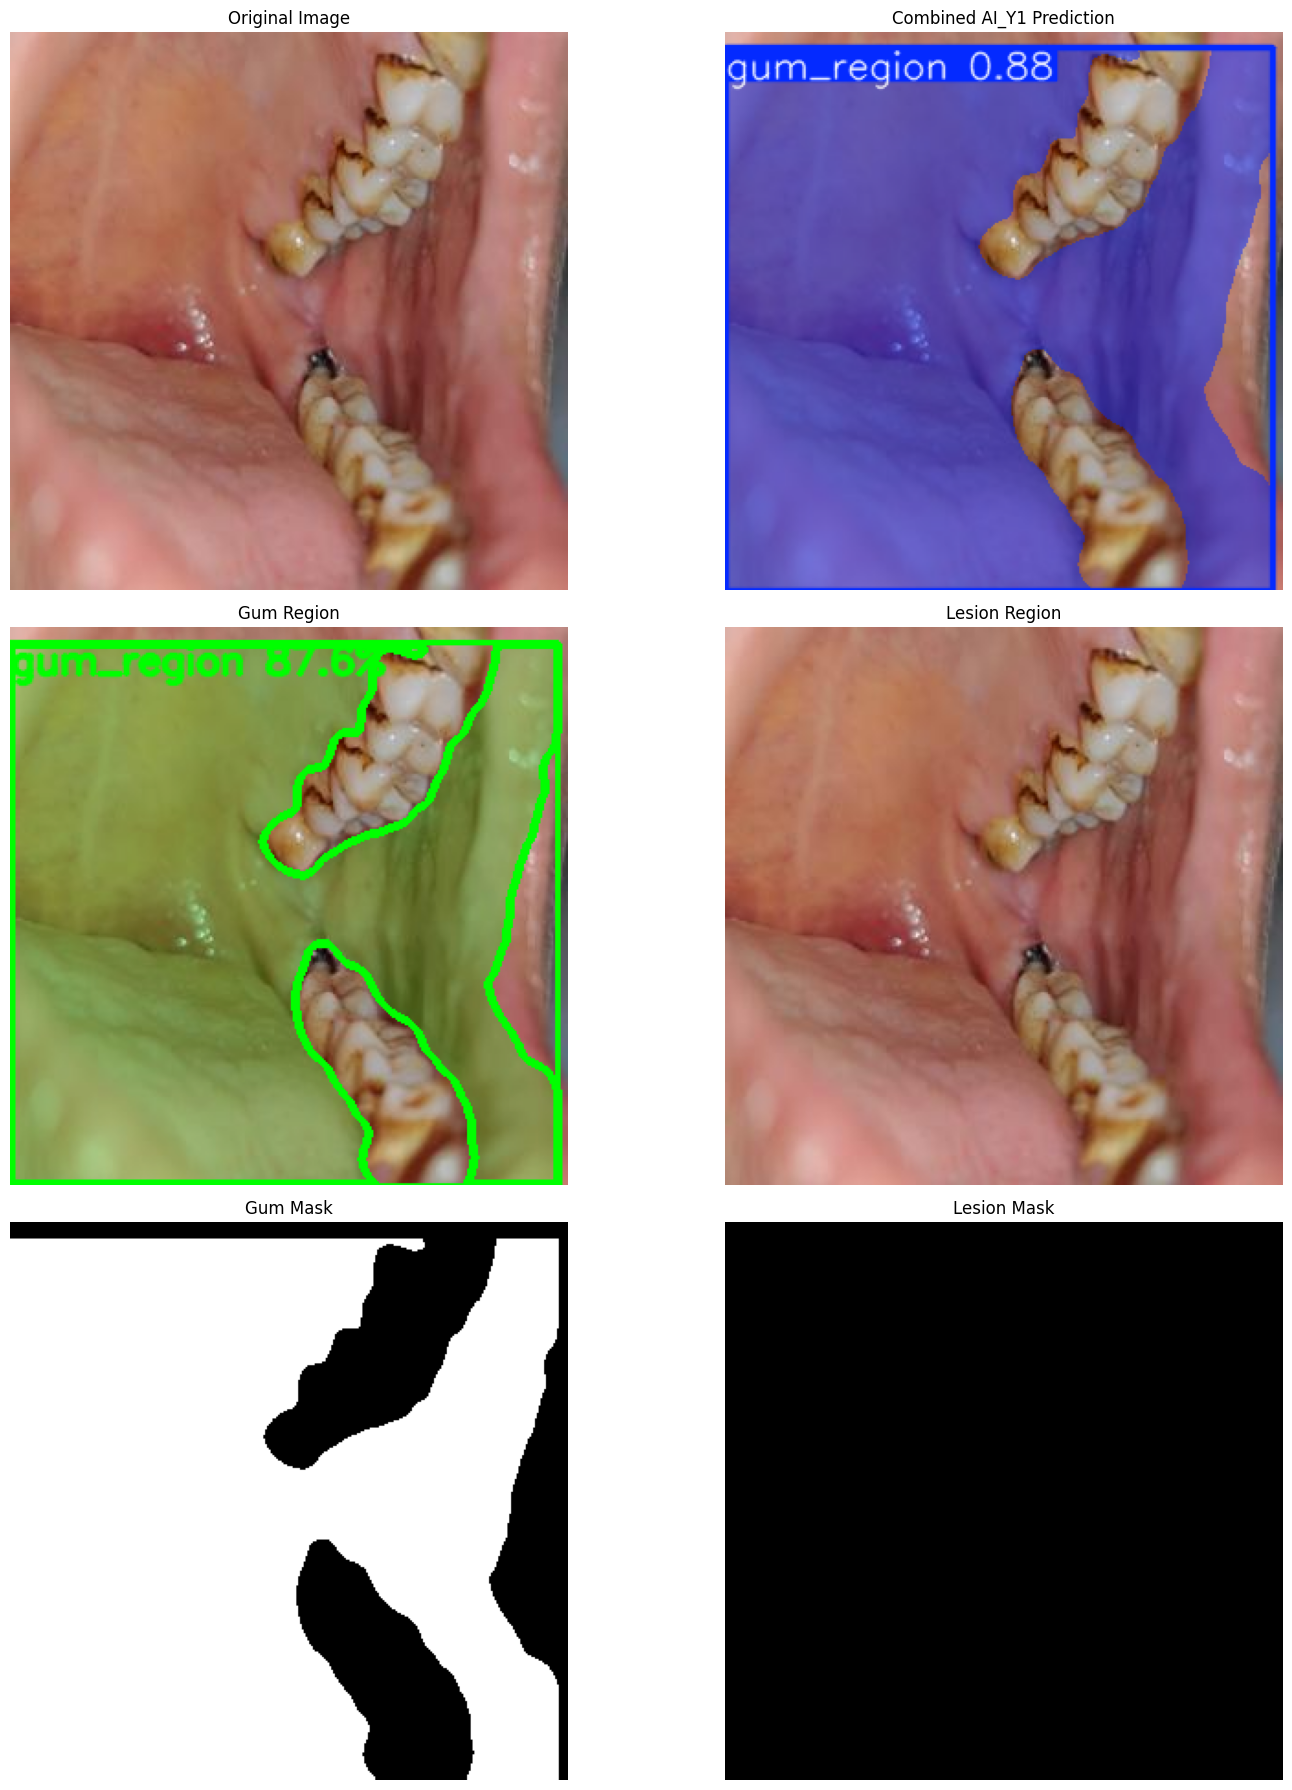


FILES SAVED
accuracy_report.json                0.38 KB
combined_prediction.png             117.11 KB
gum_region_annotated.png            122.92 KB
gum_region_mask.png                 2.11 KB
lesion_mask.png                     0.60 KB
lesion_region_annotated.png         124.35 KB
original.png                        124.35 KB
prediction.json                     30.28 KB

Complete result directory:
/content/drive/MyDrive/AI_C1 and AI_Y1/AI_Y1_Trial_Results/20260804_054446

Prediction JSON:
/content/drive/MyDrive/AI_C1 and AI_Y1/AI_Y1_Trial_Results/20260804_054446/prediction.json

Trial completed successfully.


In [ ]:
# ============================================================
# OralScan_AI — AI_Y1 COMPLETE TRIAL + ACCURACY CHECKER
#
# This single Colab cell:
# 1. Installs/imports dependencies
# 2. Loads trained AI_Y1 best.pt
# 3. Optionally validates the model on val/test dataset
# 4. Takes one uploaded image from the user
# 5. Predicts gum_region and lesion
# 6. Generates:
#       original.png
#       combined_prediction.png
#       gum_region_annotated.png
#       lesion_region_annotated.png
#       gum_region_mask.png
#       lesion_mask.png
#       lesion_crop_context.png
#       lesion_crop_masked.png
#       prediction.json
# 7. Displays all important outputs
# 8. Saves results to Google Drive
# ============================================================

# ------------------------------------------------------------
# 0. INSTALL REQUIRED PACKAGE
# ------------------------------------------------------------

!pip install -q -U ultralytics

# ------------------------------------------------------------
# 1. IMPORTS
# ------------------------------------------------------------

from google.colab import drive, files
from ultralytics import YOLO

from pathlib import Path
from datetime import datetime

import cv2
import json
import shutil
import torch
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 2. MOUNT GOOGLE DRIVE
# ------------------------------------------------------------

drive.mount("/content/drive", force_remount=False)

# ------------------------------------------------------------
# 3. CONFIGURATION
# ------------------------------------------------------------

# Final trained AI_Y1 model
MODEL_PATH = Path(
    "/content/drive/MyDrive/AI_C1 and AI_Y1/"
    "Models/AI_Y1/ai_y1_yolo26m_seg_v1_best.pt"
)

# Unified dataset YAML created during dataset preparation
#
# The code checks both possible locations.
DATA_YAML_CANDIDATES = [
    Path(
        "/content/drive/MyDrive/AI_C1 and AI_Y1/"
        "Models/AI_Y1/oralscan_ai_y1.yaml"
    ),
    Path(
        "/content/drive/MyDrive/AI_C1 and AI_Y1/"
        "AI_Y1_Training/oralscan_ai_y1.yaml"
    ),
]

# Run validation before image prediction?
#
# True  = first calculate model accuracy, then upload an image
# False = only upload and test an image
RUN_ACCURACY_CHECK = True

# Validation split:
#
# "val"  = validation set
# "test" = untouched test set
ACCURACY_SPLIT = "test"

# Inference settings
IMAGE_SIZE = 640
CONFIDENCE_THRESHOLD = 0.25
IOU_THRESHOLD = 0.60

# Use traditional one-to-many head when supported.
# It may give better recall/accuracy, although inference can be slower.
USE_ONE_TO_MANY_HEAD = True

# Lesion crop context padding.
# 0.15 means 15% extra surrounding tissue around lesion.
CONTEXT_PADDING_RATIO = 0.15

# AI_Y1 final class definition
EXPECTED_CLASSES = {
    0: "gum_region",
    1: "lesion",
}

# Timestamped output directory
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

OUTPUT_ROOT = Path(
    "/content/drive/MyDrive/AI_C1 and AI_Y1/"
    f"AI_Y1_Trial_Results/{timestamp}"
)

OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 4. BASIC VALIDATION
# ------------------------------------------------------------

print("=" * 80)
print("ORALSCAN_AI — AI_Y1 TRIAL RUN")
print("=" * 80)

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        "\nAI_Y1 best.pt model nahi mila.\n"
        f"Expected path:\n{MODEL_PATH}\n\n"
        "MODEL_PATH ko apne actual best.pt path se update karein."
    )

DATA_YAML_PATH = None

for candidate in DATA_YAML_CANDIDATES:
    if candidate.exists():
        DATA_YAML_PATH = candidate
        break

print("\nModel:", MODEL_PATH)
print("Output directory:", OUTPUT_ROOT)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    DEVICE = 0
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DEVICE = "cpu"
    print("WARNING: GPU nahi mila. Prediction CPU par chalega.")

if RUN_ACCURACY_CHECK and DATA_YAML_PATH is None:
    print(
        "\nWARNING: data.yaml nahi mila, isliye dataset accuracy check skip hoga."
    )
    print("Checked paths:")

    for candidate in DATA_YAML_CANDIDATES:
        print(" -", candidate)

    RUN_ACCURACY_CHECK = False

elif DATA_YAML_PATH is not None:
    print("Dataset YAML:", DATA_YAML_PATH)

# ------------------------------------------------------------
# 5. LOAD MODEL
# ------------------------------------------------------------

print("\nLoading AI_Y1 model...")

model = YOLO(str(MODEL_PATH))

print("Model loaded successfully.")
print("Model class names:", model.names)

normalized_model_names = {
    int(class_id): str(name).strip().lower().replace(" ", "_")
    for class_id, name in model.names.items()
}

expected_normalized = {
    0: "gum_region",
    1: "lesion",
}

if normalized_model_names != expected_normalized:
    print("\nWARNING: Model classes expected design se match nahi karti.")
    print("Expected:", expected_normalized)
    print("Found:", normalized_model_names)
    print(
        "Prediction continue hogi, lekin class mapping manually verify karein."
    )
else:
    print("Class mapping confirmed:")
    print("  Class 0 = gum_region")
    print("  Class 1 = lesion")

# ------------------------------------------------------------
# 6. OPTIONAL DATASET ACCURACY CHECK
# ------------------------------------------------------------

accuracy_report = None

if RUN_ACCURACY_CHECK:
    print("\n" + "=" * 80)
    print(f"RUNNING {ACCURACY_SPLIT.upper()} DATASET ACCURACY CHECK")
    print("=" * 80)

    validation_arguments = dict(
        data=str(DATA_YAML_PATH),
        split=ACCURACY_SPLIT,
        imgsz=IMAGE_SIZE,
        batch=4,
        device=DEVICE,
        workers=2,
        plots=True,
        project=str(OUTPUT_ROOT),
        name=f"{ACCURACY_SPLIT}_accuracy",
        exist_ok=True,
        verbose=False,
    )

    # YOLO26 supports end2end=False for one-to-many prediction/validation.
    # Fallback is included for library versions that do not expose it.
    if USE_ONE_TO_MANY_HEAD:
        validation_arguments["end2end"] = False

    try:
        metrics = model.val(**validation_arguments)

    except TypeError as error:
        print(
            "\n'end2end' argument current package version mein support "
            "nahi hua. Default validation mode use kiya ja raha hai."
        )

        validation_arguments.pop("end2end", None)
        metrics = model.val(**validation_arguments)

    # Per-class mask mAP
    per_class_mask_map = {}

    if hasattr(metrics, "seg") and metrics.seg is not None:
        for class_id, value in enumerate(metrics.seg.maps):
            class_name = model.names.get(class_id, str(class_id))
            per_class_mask_map[class_name] = float(value)

    accuracy_report = {
        "split": ACCURACY_SPLIT,

        "box_metrics": {
            "map50_95": float(metrics.box.map),
            "map50": float(metrics.box.map50),
            "map75": float(metrics.box.map75),
        },

        "mask_metrics": {
            "map50_95": float(metrics.seg.map),
            "map50": float(metrics.seg.map50),
            "map75": float(metrics.seg.map75),
            "per_class_map50_95": per_class_mask_map,
        },
    }

    print("\nMODEL ACCURACY RESULTS")
    print("-" * 80)

    print("\nBounding-box metrics:")
    print(f"  Box mAP50-95 : {metrics.box.map:.4f}")
    print(f"  Box mAP50    : {metrics.box.map50:.4f}")
    print(f"  Box mAP75    : {metrics.box.map75:.4f}")

    print("\nSegmentation-mask metrics:")
    print(f"  Mask mAP50-95: {metrics.seg.map:.4f}")
    print(f"  Mask mAP50   : {metrics.seg.map50:.4f}")
    print(f"  Mask mAP75   : {metrics.seg.map75:.4f}")

    print("\nPer-class mask mAP50-95:")

    for class_name, value in per_class_mask_map.items():
        print(f"  {class_name:15s}: {value:.4f}")

    print("\nPercentage representation:")
    print(f"  Overall mask mAP50    : {metrics.seg.map50 * 100:.2f}%")
    print(f"  Overall mask mAP50-95 : {metrics.seg.map * 100:.2f}%")

    if "gum_region" in per_class_mask_map:
        print(
            "  Gum-region mAP50-95   : "
            f"{per_class_mask_map['gum_region'] * 100:.2f}%"
        )

    if "lesion" in per_class_mask_map:
        print(
            "  Lesion mAP50-95       : "
            f"{per_class_mask_map['lesion'] * 100:.2f}%"
        )

    accuracy_json_path = OUTPUT_ROOT / "accuracy_report.json"

    with open(accuracy_json_path, "w", encoding="utf-8") as file:
        json.dump(accuracy_report, file, indent=2)

    print("\nAccuracy report saved:", accuracy_json_path)

else:
    print("\nDataset accuracy check skipped.")

# ------------------------------------------------------------
# 7. USER IMAGE UPLOAD
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("UPLOAD ONE ORAL-CAVITY IMAGE")
print("=" * 80)

print(
    "Choose an image from your computer. "
    "JPG, JPEG or PNG recommended."
)

uploaded_files = files.upload()

if not uploaded_files:
    raise RuntimeError("Koi image upload nahi hui.")

# Take the first uploaded image only
uploaded_filename = next(iter(uploaded_files.keys()))
uploaded_bytes = uploaded_files[uploaded_filename]

input_suffix = Path(uploaded_filename).suffix.lower()

if input_suffix not in {".jpg", ".jpeg", ".png", ".webp", ".bmp"}:
    raise ValueError(
        f"Unsupported image format: {input_suffix}"
    )

LOCAL_INPUT_PATH = Path("/content") / uploaded_filename

with open(LOCAL_INPUT_PATH, "wb") as file:
    file.write(uploaded_bytes)

original_image = cv2.imread(str(LOCAL_INPUT_PATH))

if original_image is None:
    raise RuntimeError(
        "Uploaded file ko OpenCV image ke roop mein read nahi kar paya."
    )

height, width = original_image.shape[:2]

print("\nUploaded image:", uploaded_filename)
print("Original resolution:", f"{width} × {height}")

# ------------------------------------------------------------
# 8. RUN PREDICTION
# ------------------------------------------------------------

print("\nRunning AI_Y1 segmentation prediction...")

prediction_arguments = dict(
    source=str(LOCAL_INPUT_PATH),
    imgsz=IMAGE_SIZE,
    conf=CONFIDENCE_THRESHOLD,
    iou=IOU_THRESHOLD,
    device=DEVICE,
    retina_masks=True,
    verbose=False,
)

if USE_ONE_TO_MANY_HEAD:
    prediction_arguments["end2end"] = False

try:
    prediction_results = model.predict(**prediction_arguments)

except TypeError:
    print(
        "'end2end' option available nahi hai. "
        "Default prediction head use kiya ja raha hai."
    )

    prediction_arguments.pop("end2end", None)
    prediction_results = model.predict(**prediction_arguments)

result = prediction_results[0]

# ------------------------------------------------------------
# 9. OUTPUT PATHS
# ------------------------------------------------------------

original_output_path = OUTPUT_ROOT / "original.png"
combined_output_path = OUTPUT_ROOT / "combined_prediction.png"

gum_annotated_path = OUTPUT_ROOT / "gum_region_annotated.png"
lesion_annotated_path = OUTPUT_ROOT / "lesion_region_annotated.png"

gum_mask_path = OUTPUT_ROOT / "gum_region_mask.png"
lesion_mask_path = OUTPUT_ROOT / "lesion_mask.png"

lesion_context_crop_path = OUTPUT_ROOT / "lesion_crop_context.png"
lesion_masked_crop_path = OUTPUT_ROOT / "lesion_crop_masked.png"

prediction_json_path = OUTPUT_ROOT / "prediction.json"

cv2.imwrite(str(original_output_path), original_image)

# Ultralytics combined rendering
combined_render = result.plot()
cv2.imwrite(str(combined_output_path), combined_render)

# Separate images
gum_annotated = original_image.copy()
lesion_annotated = original_image.copy()

# Combined binary masks
gum_combined_mask = np.zeros((height, width), dtype=np.uint8)
lesion_combined_mask = np.zeros((height, width), dtype=np.uint8)

gum_detections = []
lesion_detections = []

# ------------------------------------------------------------
# 10. PROCESS PREDICTED MASKS
# ------------------------------------------------------------

if (
    result.boxes is not None
    and result.masks is not None
    and len(result.boxes) > 0
):
    class_ids = result.boxes.cls.cpu().numpy().astype(int)
    confidences = result.boxes.conf.cpu().numpy()
    bounding_boxes = result.boxes.xyxy.cpu().numpy()
    polygons = result.masks.xy

    for detection_index, (
        class_id,
        confidence,
        bbox,
        polygon,
    ) in enumerate(
        zip(
            class_ids,
            confidences,
            bounding_boxes,
            polygons,
        ),
        start=1,
    ):
        class_name = model.names.get(
            int(class_id),
            f"class_{class_id}",
        )

        polygon_array = np.asarray(
            polygon,
            dtype=np.int32,
        )

        x1, y1, x2, y2 = bbox.astype(int)

        # Keep coordinates inside original image
        x1 = max(0, min(x1, width - 1))
        y1 = max(0, min(y1, height - 1))
        x2 = max(1, min(x2, width))
        y2 = max(1, min(y2, height))

        detection_data = {
            "instance_id": detection_index,
            "class_id": int(class_id),
            "class_name": str(class_name),
            "confidence": float(confidence),
            "confidence_percent": round(
                float(confidence) * 100,
                2,
            ),
            "bounding_box_xyxy": [
                int(x1),
                int(y1),
                int(x2),
                int(y2),
            ],
            "polygon_points": polygon_array.tolist(),
        }

        if class_id == 0:
            # ------------------------------------------------
            # GUM REGION
            # ------------------------------------------------

            overlay = gum_annotated.copy()

            cv2.fillPoly(
                overlay,
                [polygon_array],
                color=(0, 255, 0),
            )

            gum_annotated = cv2.addWeighted(
                overlay,
                0.25,
                gum_annotated,
                0.75,
                0,
            )

            cv2.polylines(
                gum_annotated,
                [polygon_array],
                isClosed=True,
                color=(0, 255, 0),
                thickness=3,
            )

            cv2.rectangle(
                gum_annotated,
                (x1, y1),
                (x2, y2),
                color=(0, 255, 0),
                thickness=2,
            )

            label = f"gum_region {confidence * 100:.1f}%"

            cv2.putText(
                gum_annotated,
                label,
                (x1, max(25, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.70,
                (0, 255, 0),
                2,
                cv2.LINE_AA,
            )

            cv2.fillPoly(
                gum_combined_mask,
                [polygon_array],
                color=255,
            )

            gum_detections.append(detection_data)

        elif class_id == 1:
            # ------------------------------------------------
            # LESION REGION
            # ------------------------------------------------

            overlay = lesion_annotated.copy()

            cv2.fillPoly(
                overlay,
                [polygon_array],
                color=(0, 0, 255),
            )

            lesion_annotated = cv2.addWeighted(
                overlay,
                0.30,
                lesion_annotated,
                0.70,
                0,
            )

            cv2.polylines(
                lesion_annotated,
                [polygon_array],
                isClosed=True,
                color=(0, 0, 255),
                thickness=3,
            )

            cv2.rectangle(
                lesion_annotated,
                (x1, y1),
                (x2, y2),
                color=(0, 0, 255),
                thickness=2,
            )

            label = f"lesion {confidence * 100:.1f}%"

            cv2.putText(
                lesion_annotated,
                label,
                (x1, max(25, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.70,
                (0, 0, 255),
                2,
                cv2.LINE_AA,
            )

            cv2.fillPoly(
                lesion_combined_mask,
                [polygon_array],
                color=255,
            )

            lesion_detections.append(detection_data)

# ------------------------------------------------------------
# 11. SAVE SEPARATE ANNOTATED IMAGES AND MASKS
# ------------------------------------------------------------

cv2.imwrite(
    str(gum_annotated_path),
    gum_annotated,
)

cv2.imwrite(
    str(lesion_annotated_path),
    lesion_annotated,
)

cv2.imwrite(
    str(gum_mask_path),
    gum_combined_mask,
)

cv2.imwrite(
    str(lesion_mask_path),
    lesion_combined_mask,
)

# ------------------------------------------------------------
# 12. CREATE CLASSIFIER LESION CROPS
# ------------------------------------------------------------

selected_lesion = None
classifier_handoff = None

if lesion_detections:
    # Highest-confidence lesion becomes default classifier input
    selected_lesion = max(
        lesion_detections,
        key=lambda item: item["confidence"],
    )

    lesion_x1, lesion_y1, lesion_x2, lesion_y2 = (
        selected_lesion["bounding_box_xyxy"]
    )

    lesion_width = max(1, lesion_x2 - lesion_x1)
    lesion_height = max(1, lesion_y2 - lesion_y1)

    padding_x = int(
        lesion_width * CONTEXT_PADDING_RATIO
    )

    padding_y = int(
        lesion_height * CONTEXT_PADDING_RATIO
    )

    crop_x1 = max(0, lesion_x1 - padding_x)
    crop_y1 = max(0, lesion_y1 - padding_y)
    crop_x2 = min(width, lesion_x2 + padding_x)
    crop_y2 = min(height, lesion_y2 + padding_y)

    # Context crop:
    # lesion plus nearby surrounding tissue
    lesion_context_crop = original_image[
        crop_y1:crop_y2,
        crop_x1:crop_x2
    ]

    # Masked full image
    masked_full_image = cv2.bitwise_and(
        original_image,
        original_image,
        mask=lesion_combined_mask,
    )

    # Masked lesion crop
    lesion_masked_crop = masked_full_image[
        crop_y1:crop_y2,
        crop_x1:crop_x2
    ]

    if lesion_context_crop.size > 0:
        cv2.imwrite(
            str(lesion_context_crop_path),
            lesion_context_crop,
        )

    if lesion_masked_crop.size > 0:
        cv2.imwrite(
            str(lesion_masked_crop_path),
            lesion_masked_crop,
        )

    classifier_handoff = {
        "ready": True,
        "recommended_classifier_input": str(
            lesion_context_crop_path
        ),
        "additional_masked_crop": str(
            lesion_masked_crop_path
        ),
        "lesion_mask": str(lesion_mask_path),
        "selected_lesion_confidence": (
            selected_lesion["confidence"]
        ),
        "selected_lesion_confidence_percent": (
            selected_lesion["confidence_percent"]
        ),
        "selected_lesion_bbox_xyxy": (
            selected_lesion["bounding_box_xyxy"]
        ),
        "context_crop_bbox_xyxy": [
            crop_x1,
            crop_y1,
            crop_x2,
            crop_y2,
        ],
    }

else:
    classifier_handoff = {
        "ready": False,
        "reason": "NO_LESION_DETECTED",
        "recommended_classifier_input": None,
    }

# ------------------------------------------------------------
# 13. BUILD FINAL PREDICTION REPORT
# ------------------------------------------------------------

best_gum_confidence = (
    max(
        detection["confidence"]
        for detection in gum_detections
    )
    if gum_detections
    else None
)

best_lesion_confidence = (
    max(
        detection["confidence"]
        for detection in lesion_detections
    )
    if lesion_detections
    else None
)

prediction_report = {
    "project": "OralScan_AI",
    "model_id": "AI_Y1",
    "model_path": str(MODEL_PATH),
    "input_file": uploaded_filename,
    "input_resolution": {
        "width": width,
        "height": height,
    },
    "inference_settings": {
        "imgsz": IMAGE_SIZE,
        "confidence_threshold": CONFIDENCE_THRESHOLD,
        "iou_threshold": IOU_THRESHOLD,
    },
    "class_mapping": {
        "0": "gum_region",
        "1": "lesion",
    },
    "gum_region": {
        "detected": len(gum_detections) > 0,
        "count": len(gum_detections),
        "best_confidence": best_gum_confidence,
        "best_confidence_percent": (
            round(best_gum_confidence * 100, 2)
            if best_gum_confidence is not None
            else None
        ),
        "detections": gum_detections,
        "annotated_image": str(gum_annotated_path),
        "mask_image": str(gum_mask_path),
    },
    "lesion": {
        "detected": len(lesion_detections) > 0,
        "count": len(lesion_detections),
        "best_confidence": best_lesion_confidence,
        "best_confidence_percent": (
            round(best_lesion_confidence * 100, 2)
            if best_lesion_confidence is not None
            else None
        ),
        "detections": lesion_detections,
        "annotated_image": str(
            lesion_annotated_path
        ),
        "mask_image": str(lesion_mask_path),
    },
    "classifier_handoff": classifier_handoff,
    "dataset_accuracy": accuracy_report,
    "outputs": {
        "original": str(original_output_path),
        "combined_prediction": str(
            combined_output_path
        ),
        "gum_region_annotated": str(
            gum_annotated_path
        ),
        "lesion_region_annotated": str(
            lesion_annotated_path
        ),
        "gum_region_mask": str(gum_mask_path),
        "lesion_mask": str(lesion_mask_path),
        "lesion_crop_context": (
            str(lesion_context_crop_path)
            if lesion_context_crop_path.exists()
            else None
        ),
        "lesion_crop_masked": (
            str(lesion_masked_crop_path)
            if lesion_masked_crop_path.exists()
            else None
        ),
    },
}

with open(
    prediction_json_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        prediction_report,
        file,
        indent=2,
    )

# ------------------------------------------------------------
# 14. PRINT HUMAN-READABLE RESULT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("AI_Y1 PREDICTION RESULT")
print("=" * 80)

if gum_detections:
    print(
        f"\nGum region detected: YES "
        f"({len(gum_detections)} instance)"
    )
    print(
        "Best gum confidence:",
        f"{best_gum_confidence * 100:.2f}%",
    )
else:
    print("\nGum region detected: NO")

if lesion_detections:
    print(
        f"\nLesion detected: YES "
        f"({len(lesion_detections)} instance)"
    )
    print(
        "Best lesion confidence:",
        f"{best_lesion_confidence * 100:.2f}%",
    )

    print("\nClassifier handoff ready: YES")
    print(
        "Recommended AI_C1 input:",
        lesion_context_crop_path,
    )
    print(
        "Masked lesion crop:",
        lesion_masked_crop_path,
    )

else:
    print("\nLesion detected: NO")
    print("Classifier handoff ready: NO")
    print(
        "Reason: AI_Y1 ko confidence threshold ke upar "
        "koi lesion nahi mila."
    )

if (
    best_gum_confidence is not None
    and best_gum_confidence < 0.60
):
    print(
        "\nWARNING: Gum-region confidence 60% se kam hai. "
        "Manual review recommended."
    )

if (
    best_lesion_confidence is not None
    and best_lesion_confidence < 0.60
):
    print(
        "\nWARNING: Lesion confidence 60% se kam hai. "
        "Classifier ko bhejne se pehle manual review recommended."
    )

# ------------------------------------------------------------
# 15. DISPLAY OUTPUTS
# ------------------------------------------------------------

def bgr_to_rgb(image):
    return cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB,
    )


display_items = [
    (
        "Original Image",
        original_image,
        "bgr",
    ),
    (
        "Combined AI_Y1 Prediction",
        combined_render,
        "bgr",
    ),
    (
        "Gum Region",
        gum_annotated,
        "bgr",
    ),
    (
        "Lesion Region",
        lesion_annotated,
        "bgr",
    ),
    (
        "Gum Mask",
        gum_combined_mask,
        "gray",
    ),
    (
        "Lesion Mask",
        lesion_combined_mask,
        "gray",
    ),
]

if lesion_context_crop_path.exists():
    context_crop_display = cv2.imread(
        str(lesion_context_crop_path)
    )

    display_items.append(
        (
            "Classifier Input: Context Crop",
            context_crop_display,
            "bgr",
        )
    )

if lesion_masked_crop_path.exists():
    masked_crop_display = cv2.imread(
        str(lesion_masked_crop_path)
    )

    display_items.append(
        (
            "Masked Lesion Crop",
            masked_crop_display,
            "bgr",
        )
    )

columns = 2
rows = int(np.ceil(len(display_items) / columns))

plt.figure(figsize=(16, rows * 6))

for index, (
    title,
    image,
    image_type,
) in enumerate(
    display_items,
    start=1,
):
    plt.subplot(rows, columns, index)

    if image_type == "gray":
        plt.imshow(
            image,
            cmap="gray",
            vmin=0,
            vmax=255,
        )
    else:
        plt.imshow(bgr_to_rgb(image))

    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 16. FINAL OUTPUT SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("FILES SAVED")
print("=" * 80)

for output_file in sorted(OUTPUT_ROOT.iterdir()):
    if output_file.is_file():
        print(
            f"{output_file.name:35s} "
            f"{output_file.stat().st_size / 1024:.2f} KB"
        )

print("\nComplete result directory:")
print(OUTPUT_ROOT)

print("\nPrediction JSON:")
print(prediction_json_path)

print("\nTrial completed successfully.")

## UI Code

In [ ]:
ś# ================================================================
# OralScan_AI — AI_Y1 SAFE COLAB TRIAL INTERFACE (ONE CELL)
# Colab-compatible, simplified and robust
# ================================================================

!pip install -q -U ultralytics gradio opencv-python-headless pillow

from pathlib import Path
import traceback
import cv2
import gradio as gr
import numpy as np
import torch
from PIL import Image
from ultralytics import YOLO
from google.colab import drive

# -------------------- MOUNT DRIVE --------------------
if not Path("/content/drive/MyDrive").exists():
    drive.mount("/content/drive")

PROJECT_ROOT = Path("/content/drive/MyDrive/AI_C1 and AI_Y1")

MODEL_CANDIDATES = [
    PROJECT_ROOT / "Models/AI_Y1/ai_y1_yolo26m_seg_v1_best.pt",
    PROJECT_ROOT / "AI_Y1_Training/AI_Y1_YOLO26M_SEG_V1/weights/best.pt",
    PROJECT_ROOT / "AI_Y1_Training/AI_Y1_YOLO26M_SEG_V1/weights/last.pt",
]

MODEL_PATH = next((p for p in MODEL_CANDIDATES if p.exists()), None)

if MODEL_PATH is None:
    raise FileNotFoundError(
        "best.pt nahi mila. MODEL_CANDIDATES mein exact path add karein:\n" +
        "\n".join(str(p) for p in MODEL_CANDIDATES)
    )

DEVICE = 0 if torch.cuda.is_available() else "cpu"
MODEL = YOLO(str(MODEL_PATH))

print("Loaded model:", MODEL_PATH)
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Classes:", MODEL.names)

# -------------------- HELPERS --------------------
def to_rgb_numpy(image):
    if image is None:
        raise ValueError("Image upload karein.")

    if isinstance(image, Image.Image):
        arr = np.array(image.convert("RGB"))
    else:
        arr = np.asarray(image)

    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255).astype(np.uint8)

    if arr.ndim == 2:
        arr = cv2.cvtColor(arr, cv2.COLOR_GRAY2RGB)
    elif arr.ndim == 3 and arr.shape[2] == 4:
        arr = cv2.cvtColor(arr, cv2.COLOR_RGBA2RGB)

    if arr.ndim != 3 or arr.shape[2] != 3:
        raise ValueError(f"Unsupported image shape: {arr.shape}")

    return arr

def as_pil(arr):
    arr = np.asarray(arr)
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255).astype(np.uint8)
    if arr.ndim == 2:
        return Image.fromarray(arr, mode="L")
    return Image.fromarray(arr, mode="RGB")

def placeholder(text, width=640, height=420):
    canvas = np.full((height, width, 3), 245, dtype=np.uint8)
    cv2.putText(
        canvas,
        text,
        (25, height // 2),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.72,
        (70, 70, 70),
        2,
        cv2.LINE_AA,
    )
    return as_pil(canvas)

def overlay_polygon(image, polygon, color, alpha):
    overlay = image.copy()
    cv2.fillPoly(overlay, [polygon], color)
    result = cv2.addWeighted(overlay, alpha, image, 1.0 - alpha, 0)
    cv2.polylines(result, [polygon], True, color, 3, cv2.LINE_AA)
    return result

def add_text(image, text, x, y, color):
    x = max(5, int(x))
    y = max(28, int(y))
    cv2.putText(
        image,
        text,
        (x, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.68,
        color,
        3,
        cv2.LINE_AA,
    )
    cv2.putText(
        image,
        text,
        (x, y),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.68,
        (255, 255, 255),
        1,
        cv2.LINE_AA,
    )

def create_crops(original, mask, bbox, padding_ratio):
    h, w = original.shape[:2]
    x1, y1, x2, y2 = [int(v) for v in bbox]

    bw = max(1, x2 - x1)
    bh = max(1, y2 - y1)
    px = max(8, int(bw * padding_ratio))
    py = max(8, int(bh * padding_ratio))

    x1 = max(0, x1 - px)
    y1 = max(0, y1 - py)
    x2 = min(w, x2 + px)
    y2 = min(h, y2 + py)

    context_crop = original[y1:y2, x1:x2].copy()

    masked_full = cv2.bitwise_and(
        original,
        original,
        mask=mask,
    )
    masked_crop = masked_full[y1:y2, x1:x2].copy()
    mask_crop = mask[y1:y2, x1:x2].copy()

    if context_crop.size == 0:
        return (
            placeholder("Invalid context crop"),
            placeholder("Invalid masked crop"),
            placeholder("Invalid mask"),
        )

    return (
        as_pil(context_crop),
        as_pil(masked_crop),
        as_pil(mask_crop),
    )

# -------------------- PREDICTION --------------------
def run_prediction(image, conf_threshold, iou_threshold, crop_padding):
    try:
        original = to_rgb_numpy(image)
        h, w = original.shape[:2]

        results = MODEL.predict(
            source=original,
            imgsz=640,
            conf=float(conf_threshold),
            iou=float(iou_threshold),
            device=DEVICE,
            retina_masks=True,
            verbose=False,
        )

        result = results[0]

        combined = original.copy()
        gum_view = original.copy()
        lesion_view = original.copy()

        gum_items = []
        lesion_items = []

        if (
            result.boxes is not None
            and result.masks is not None
            and len(result.boxes) > 0
        ):
            classes = result.boxes.cls.cpu().numpy().astype(int)
            scores = result.boxes.conf.cpu().numpy().astype(float)
            boxes = result.boxes.xyxy.cpu().numpy()
            polygons = result.masks.xy

            n = min(len(classes), len(scores), len(boxes), len(polygons))

            for idx in range(n):
                cls_id = int(classes[idx])
                score = float(scores[idx])

                polygon = np.asarray(polygons[idx], dtype=np.float32)
                if polygon.ndim != 2 or polygon.shape[0] < 3:
                    continue

                polygon[:, 0] = np.clip(polygon[:, 0], 0, w - 1)
                polygon[:, 1] = np.clip(polygon[:, 1], 0, h - 1)
                polygon = np.round(polygon).astype(np.int32)

                x1, y1, x2, y2 = boxes[idx]
                x1 = max(0, min(w - 1, int(round(x1))))
                y1 = max(0, min(h - 1, int(round(y1))))
                x2 = max(x1 + 1, min(w, int(round(x2))))
                y2 = max(y1 + 1, min(h, int(round(y2))))

                binary_mask = np.zeros((h, w), dtype=np.uint8)
                cv2.fillPoly(binary_mask, [polygon], 255)

                item = {
                    "score": score,
                    "bbox": [x1, y1, x2, y2],
                    "polygon": polygon,
                    "mask": binary_mask,
                }

                if cls_id == 0:
                    color = (20, 180, 80)
                    gum_view = overlay_polygon(gum_view, polygon, color, 0.25)
                    combined = overlay_polygon(combined, polygon, color, 0.18)
                    cv2.rectangle(gum_view, (x1, y1), (x2, y2), color, 2)
                    add_text(gum_view, f"Gum {score*100:.1f}%", x1, y1, color)
                    add_text(combined, f"Gum {score*100:.1f}%", x1, y1, color)
                    gum_items.append(item)

                elif cls_id == 1:
                    color = (220, 45, 45)
                    lesion_view = overlay_polygon(lesion_view, polygon, color, 0.30)
                    combined = overlay_polygon(combined, polygon, color, 0.24)
                    cv2.rectangle(lesion_view, (x1, y1), (x2, y2), color, 2)
                    add_text(lesion_view, f"Lesion {score*100:.1f}%", x1, y1, color)
                    add_text(combined, f"Lesion {score*100:.1f}%", x1, y1, color)
                    lesion_items.append(item)

        gum_items.sort(key=lambda x: x["score"], reverse=True)
        lesion_items.sort(key=lambda x: x["score"], reverse=True)

        best_gum = gum_items[0] if gum_items else None
        best_lesion = lesion_items[0] if lesion_items else None

        if best_gum is None:
            gum_output = placeholder("No gum region detected", w, h)
            gum_conf = "Not detected"
        else:
            gum_output = as_pil(gum_view)
            gum_conf = f"{best_gum['score']*100:.2f}%"

        if best_lesion is None:
            lesion_output = placeholder("No lesion detected", w, h)
            context_output = placeholder("No classifier crop")
            masked_output = placeholder("No masked crop")
            mask_output = placeholder("No lesion mask")
            lesion_conf = "Not detected"
            handoff = "AI_C1 handoff available nahi hai because lesion detect nahi hua."
        else:
            lesion_output = as_pil(lesion_view)
            context_output, masked_output, mask_output = create_crops(
                original,
                best_lesion["mask"],
                best_lesion["bbox"],
                float(crop_padding),
            )
            lesion_conf = f"{best_lesion['score']*100:.2f}%"
            handoff = "Lesion context crop AI_C1 classifier ke input ke liye ready hai."

        summary = (
            "## AI_Y1 Result\n\n"
            f"- Gum detections: **{len(gum_items)}**\n"
            f"- Lesion detections: **{len(lesion_items)}**\n"
            f"- Best gum confidence: **{gum_conf}**\n"
            f"- Best lesion confidence: **{lesion_conf}**\n"
            f"- Input size: **{w} × {h}**\n"
            f"- Inference size: **640 × 640**\n"
            f"- Device: **{DEVICE}**\n\n"
            f"### Classifier handoff\n{handoff}\n\n"
            "> Confidence uploaded image ki prediction certainty hai; "
            "overall model accuracy nahi."
        )

        return (
            as_pil(original),
            as_pil(combined),
            gum_output,
            lesion_output,
            context_output,
            masked_output,
            mask_output,
            summary,
        )

    except Exception as error:
        traceback.print_exc()

        p = placeholder("Prediction failed")
        error_text = (
            "## Prediction failed\n\n"
            f"**{type(error).__name__}:** `{str(error)}`\n\n"
            "Colab cell output mein complete traceback dekhein."
        )

        try:
            original_output = as_pil(to_rgb_numpy(image))
        except Exception:
            original_output = p

        return (
            original_output,
            p,
            p,
            p,
            p,
            p,
            p,
            error_text,
        )

# -------------------- GRADIO APP --------------------
with gr.Blocks(title="OralScan_AI AI_Y1 Trial") as demo:
    gr.Markdown(
        "# OralScan_AI — AI_Y1 Trial\n"
        "Image upload karein aur prediction run karein."
    )

    with gr.Row():
        with gr.Column():
            image_input = gr.Image(
                type="pil",
                label="Oral image",
                sources=["upload", "webcam"],
            )
            conf_input = gr.Slider(
                minimum=0.05,
                maximum=0.95,
                value=0.25,
                step=0.05,
                label="Confidence threshold",
            )
            iou_input = gr.Slider(
                minimum=0.10,
                maximum=0.90,
                value=0.60,
                step=0.05,
                label="IoU threshold",
            )
            padding_input = gr.Slider(
                minimum=0.00,
                maximum=0.40,
                value=0.12,
                step=0.02,
                label="Classifier crop padding",
            )
            predict_button = gr.Button(
                "Run AI_Y1 Prediction",
                variant="primary",
            )

        with gr.Column():
            combined_output = gr.Image(
                type="pil",
                label="Combined: green=gum, red=lesion",
            )

    with gr.Row():
        original_output = gr.Image(type="pil", label="Original")
        gum_output = gr.Image(type="pil", label="Gum region")
        lesion_output = gr.Image(type="pil", label="Lesion region")

    gr.Markdown("## AI_C1 classifier handoff")

    with gr.Row():
        context_output = gr.Image(
            type="pil",
            label="Lesion context crop — primary AI_C1 input",
        )
        masked_output = gr.Image(
            type="pil",
            label="Masked lesion crop",
        )
        mask_output = gr.Image(
            type="pil",
            label="Binary lesion mask",
        )

    summary_output = gr.Markdown("Image upload karein.")

    predict_button.click(
        fn=run_prediction,
        inputs=[
            image_input,
            conf_input,
            iou_input,
            padding_input,
        ],
        outputs=[
            original_output,
            combined_output,
            gum_output,
            lesion_output,
            context_output,
            masked_output,
            mask_output,
            summary_output,
        ],
    )

demo.queue(
    default_concurrency_limit=1,
    max_size=5,
).launch(
    share=True,
    inline=False,
    debug=True,
    show_error=True,
)

NameError: name 'ś' is not defined

## Model loaded

Model path: /content/drive/MyDrive/AI_C1 and AI_Y1/ai_y1.pt
Class mapping: {0: 'lesion', 1: 'processing_area'}


## Upload one image

Saving 1M (2).jpg to 1M (2).jpg
Image name: 1M (2).jpg
Original size: 304 × 304


## Inference summary

YOLO SEGMENTATION OUTPUT
Image                  : 1M (2).jpg
Image size             : 304 × 304
Confidence threshold   : 0.25
Total detections       : 1
Lesion detections      : 0
Processing detections  : 1

Detection #1
------------------------------------------------------------------------
Class                  : processing_area (ID 1)
Confidence             : 0.9463 (94.63%)
Bounding box XYXY      : [0.0, 4.03, 298.0, 304.0]
Bounding box size      : 298.0 × 300.0
Polygon points         : 315
Binary mask available  : True


## Annotated prediction

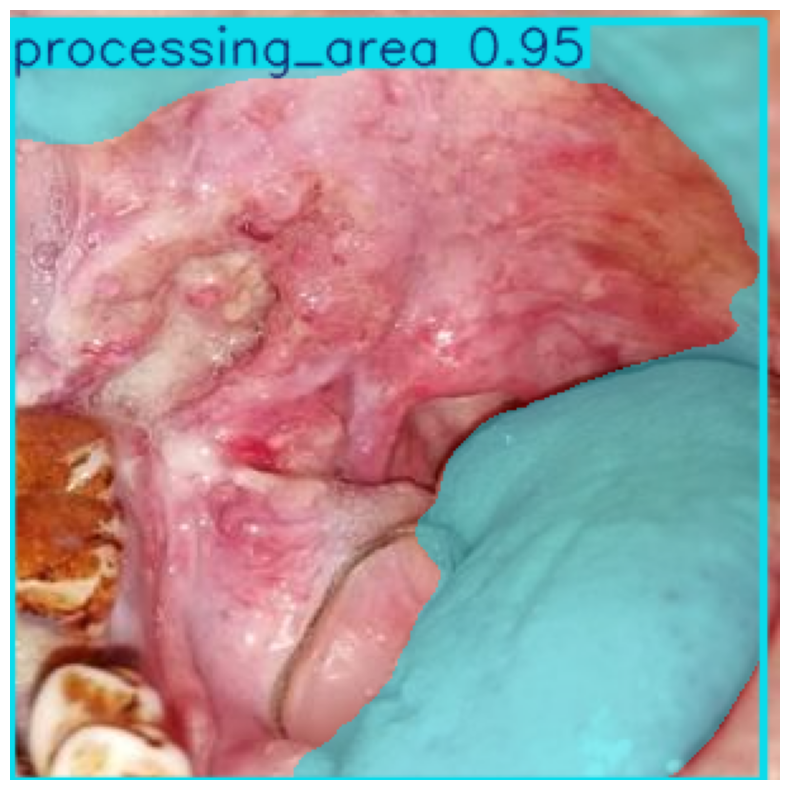

### Detection 1: processing_area — 94.63%

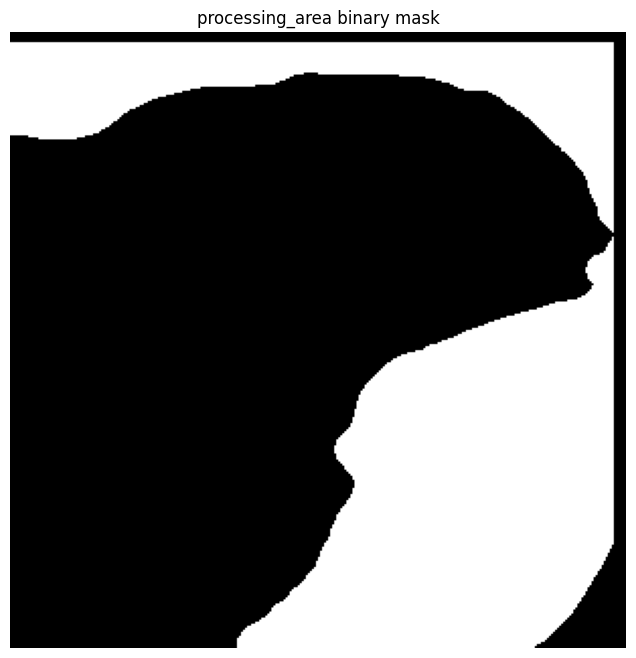

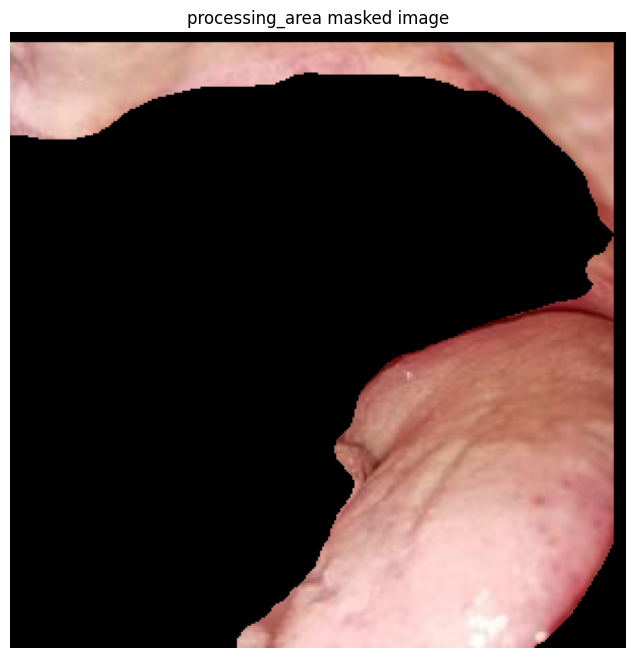

In [2]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 30.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 10.2 MB/s eta 0:00:00


In [3]:
import torch

MODEL_PATH = "/content/sample_data/ai_y1.pt"   # apna model path

ckpt = torch.load(MODEL_PATH, map_location="cpu", weights_only=False)

print("Checkpoint keys:")
print(ckpt.keys())

print("\n--- TRAIN ARGS ---")
print(ckpt.get("train_args", "train_args not found"))

print("\n--- DATE ---")
print(ckpt.get("date", "date not found"))

print("\n--- ULTRALYTICS VERSION ---")
print(ckpt.get("version", "version not found"))

print("\n--- MODEL CLASS NAMES ---")
model = ckpt.get("model")
if model is not None:
    print(getattr(model, "names", "names not found"))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Checkpoint keys:
dict_keys(['date', 'version', 'license', 'docs', 'epoch', 'best_fitness', 'model', 'ema', 'updates', 'optimizer', 'scaler', 'train_args', 'train_metrics', 'train_results', 'git'])

--- TRAIN ARGS ---
{'task': 'segment', 'mode': 'train', 'model': 'yolo26m-seg.pt', 'data': '/content/oralscan_training_workspace/merged_dataset/data.yaml', 'epochs': 300, 'time': None, 'patience': 40, 'batch': 16, 'imgsz': 640, 'save': True, 'save_period': -1, 'cache': False, 'device': '0', 'workers': 8, 'project': '/content/oralscan_training_workspace/training_runs', 'name': 'oralscan_yolo26m_seg', 'exist_ok': True, 'pretrained': True, 'cls_remap': True, 'optimizer': 'AdamW', 'verbose': True, 'seed': 42